# Main-paper role

Result: pre-insight ERP cluster over F3/C3/P3, -450 to -297 ms, cluster p = .037.

This notebook builds insight-locked ERPs around confirmed aha markers and runs the spatiotemporal cluster-permutation analysis.


In [2]:
import mne
%load_ext autoreload
%autoreload 2
from utils import *
import warnings

mne.set_log_level('ERROR')
warnings.filterwarnings("ignore")
# --- Setup ---
base_path = '/Users/athenasaghi/Desktop/CleanDATA/clean/'
base_path_ICA = '/Users/athenasaghi/Desktop/CleanDATA/CLEAN_BASELINES/ICA/'

#  control files 25
# control_files = [
#     'P4_control_A1_postcleaning4.set', 
#     'P4_control_B4_postcleaning4.set',
#     'P5_control_A2_postcleaning4.set', 
#     'P5_control_B3_postcleaning4.set',
#     'P13_control_A2_postcleaning1.set', 
#     'P13_control_B3_postcleaning1.set',
#     'P9_control_A3_postcleaning1.set', 
#     'P9_control_B3_postcleaning1.set',
#     'P10_control_A3_postcleaning1.set', 
#     'P10_control_B2_postcleaning1.set',
#     'P14_control_A4_postcleaning1.set',
#     'P14_control_B4_postcleaning1.set',
#     'P15_control_A2_postcleaning1.set',
#     'P15_control_B1_postcleaning1.set',
#     'P16_control_A2_postcleaning1.set', 
#     'P16_control_B3_postcleaning1.set',
#     'P17_control_A2_postcleaning1.set', 
#     'P17_control_A3_postcleaning1.set',
#     'P18_control_A3_postcleaning1.set', 
#     'P18_control_B2_postcleaning1.set',
#     'P21_control_B1_postcleaning1.set', 
#     'P22_control_A1_postcleaning1.set',
#     'P22_control_B4_postcleaning1.set',
#     'P23_control_A1_postcleaning1.set',
#     'P23_control_B3_postcleaning1.set'
# ]

# # treatment files 22
# treatment_files = [
#     "P22_treatment_B3_postcleaning1.set",
#     "P4_treatment_A4_postcleaning4.set",
#     "P4_treatment_B3_postcleaning3.set",
#     "P4_treatment_B3_postcleaning4.set",
#     "P5_treatment_A1_postcleaning4.set",
#     "P5_treatment_B4_postcleaning4.set",
#     "P9_treatment_A4_postcleaning1.set",
#     "P9_treatment_B2_postcleaning1.set",
#     "P10_treatment_A2_postcleaning1.set",
#     "P10_treatment_B3_postcleaning1.set",
#     "P13_treatment_A4_postcleaning1.set",
#     "P13_treatment_B1_postcleaning1.set",
#     "P14_treatment_A2_postcleaning1.set",
#     "P15_treatment_A4_postcleaning1.set",
#     "P15_treatment_B2_postcleaning1.set",
#     "P16_treatment_A4_postcleaning1.set",
#     "P16_treatment_B2_postcleaning1.set",
#     "P17_treatment_A1_postcleaning1.set",
#     "P17_treatment_B1_postcleaning1.set",
#     "P18_treatment_A2_postcleaning1.set",
#     "P18_treatment_B3_postcleaning1.set",
# ]

control_files, treatment_files = get_files_with_event_100(base_path)



# Define the 21 channels you want to keep
standard_chans = [
    'P3', 'C3', 'F3', 'Fz', 'F4', 'C4', 'P4', 'Cz', 'A1', 'Fp1', 
    'Fp2', 'T7', 'P7', 'O1', 'O2', 'F7', 'F8', 'A2', 'P8', 'T8', 'Pz'
]

# Process treatment files
task_evokeds_treatment, base_evokeds_treatment , epochs_t_treatment, base_epochs_list_treatment = extract_evokeds_epochs(
    treatment_files, base_path, base_path_ICA, standard_chans
)
task_evokeds_control, base_evokeds_control , epochs_t_control, base_epochs_list_control = extract_evokeds_epochs(
    control_files, base_path, base_path_ICA, standard_chans
)
ga_task_treatment = mne.grand_average(task_evokeds_treatment)
ga_base_treatment = mne.grand_average(base_evokeds_treatment)
ga_task_control = mne.grand_average(task_evokeds_control)
ga_base_control = mne.grand_average(base_evokeds_control)

# print("totoal sessions processed:", len(treatment_files))

✗ Trigger '100' not in P11_treatment_B3_postcleaning1.set. Available: [np.str_('1'), np.str_('16'), np.str_('2'), np.str_('4'), np.str_('6'), np.str_('boundary')]
✗ Trigger '100' not in P12_control_A3_postcleaning1.set. Available: [np.str_('1'), np.str_('2'), np.str_('3'), np.str_('4'), np.str_('6'), np.str_('boundary')]
✗ Trigger '100' not in P12_control_B1_postcleaning1.set. Available: [np.str_('1'), np.str_('2'), np.str_('3'), np.str_('4'), np.str_('6'), np.str_('boundary')]
✗ Trigger '100' not in P14_treatment_B1_postcleaning1.set. Available: [np.str_('1'), np.str_('16'), np.str_('2'), np.str_('3'), np.str_('boundary')]
✗ Trigger '100' not in P21_control_A3_postcleaning1.set. Available: [np.str_('2'), np.str_('4'), np.str_('6'), np.str_('boundary')]
✗ Trigger '100' not in P21_treatment_A4_postcleaning1.set. Available: [np.str_('1'), np.str_('16'), np.str_('2'), np.str_('3'), np.str_('4'), np.str_('6'), np.str_('boundary')]
✗ Trigger '100' not in P21_treatment_B2_postcleaning4.set. 

In [3]:
len(control_files), len(treatment_files)

(33, 28)

# GrandAvgERP Topomaps during a window, in different bands

## Control 

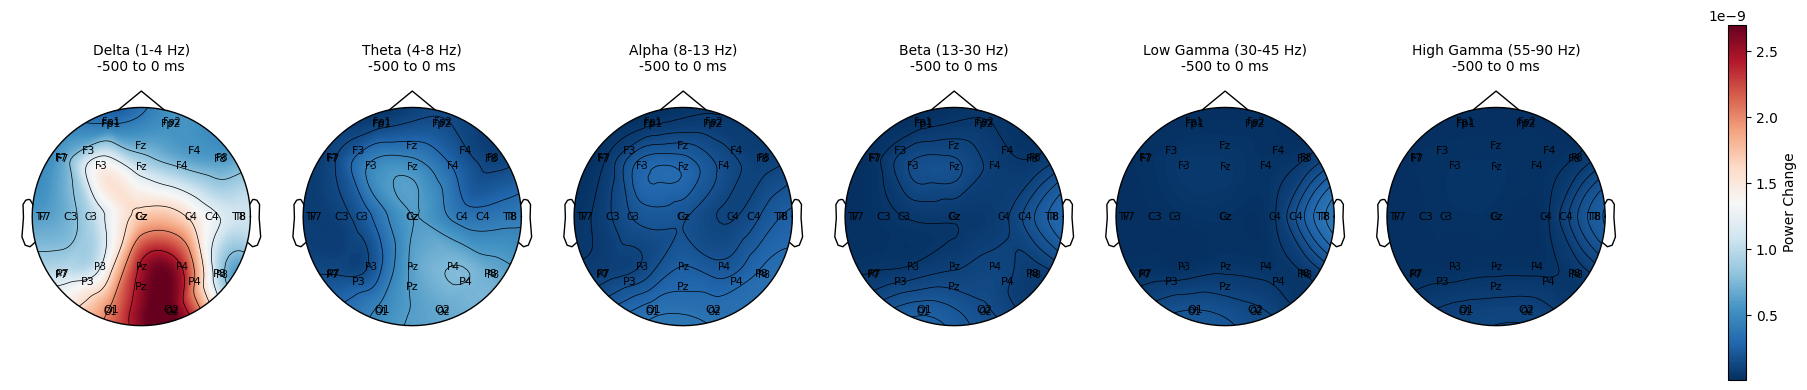

In [4]:
tfr_task_control = plot_tfr_bands(epochs_t_control,isplot=False)
fig, axes = plot_tfr_bands_topomap(tfr_task_control, ga_task_control, t_start=-0.5, t_stop=0)
plt.show()
# plt.savefig('tfr_topomap_control.png')
# time_slices = [-0.4,-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3, 0.4]
# plot_erp_topomaps(ga_task_control, time_slices)

## Treatment

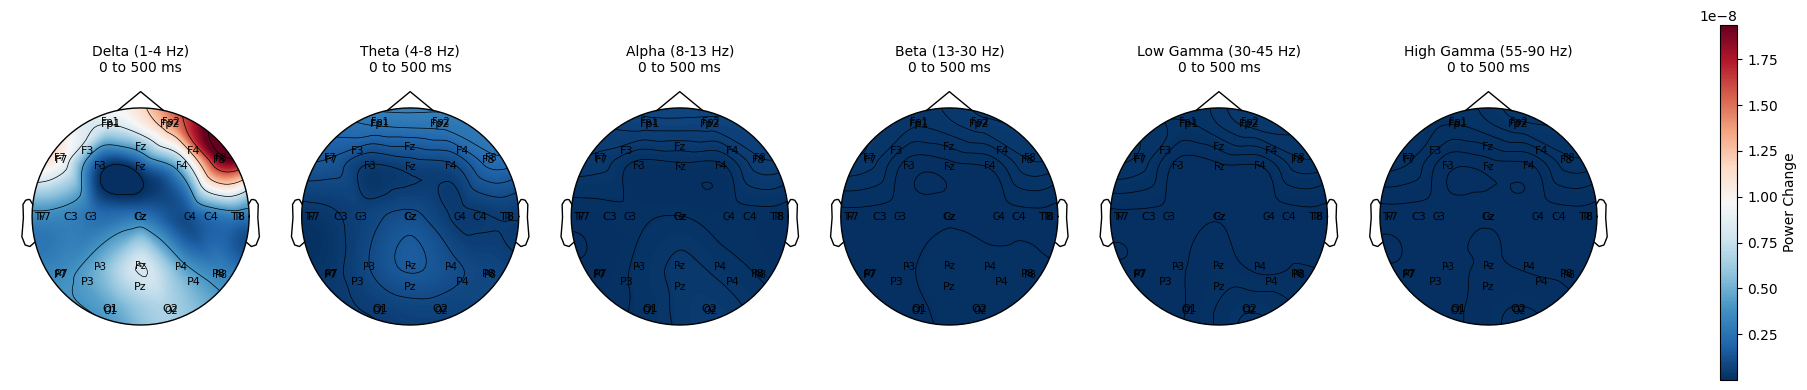

In [5]:
tfr_task_treatment = plot_tfr_bands(epochs_t_treatment,isplot=False)
fig, axes = plot_tfr_bands_topomap(tfr_task_treatment, ga_task_treatment, t_start=0, t_stop=0.5)
plt.show()


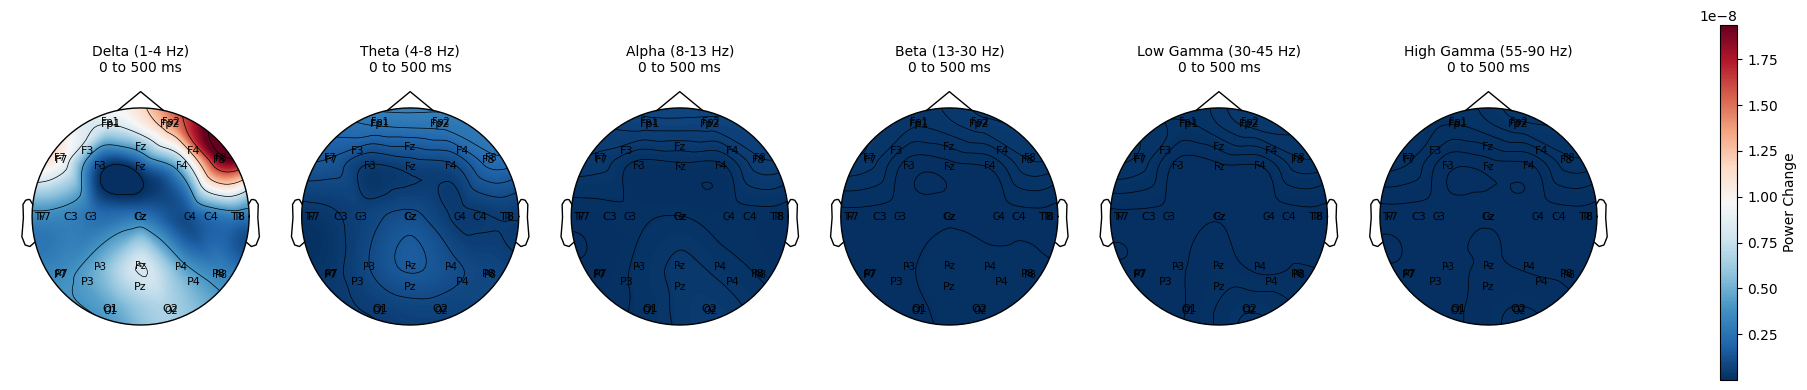

In [6]:
tfr_task_treatment = plot_tfr_bands(epochs_t_treatment,isplot=False)
fig, axes = plot_tfr_bands_topomap(tfr_task_treatment, ga_task_treatment, t_start=0, t_stop=0.5)
plt.show()


# GrandAvgERP Topomaps in a time point, across bands

## Treatment

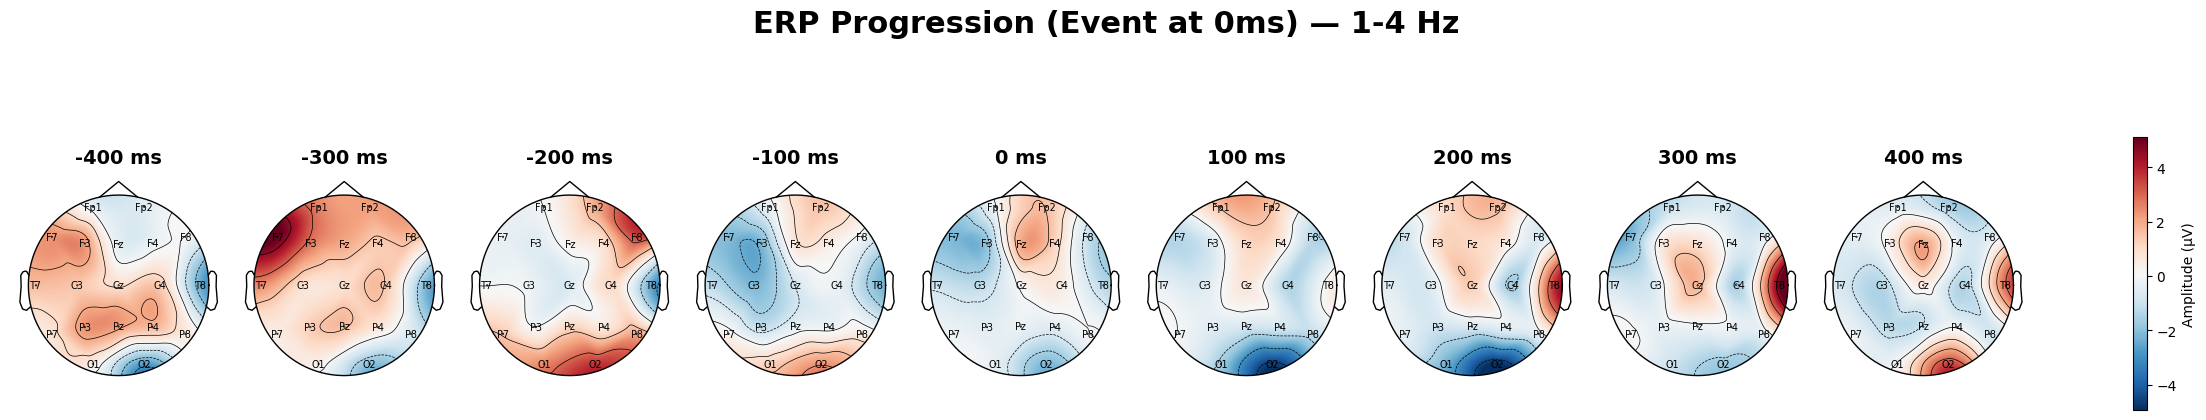

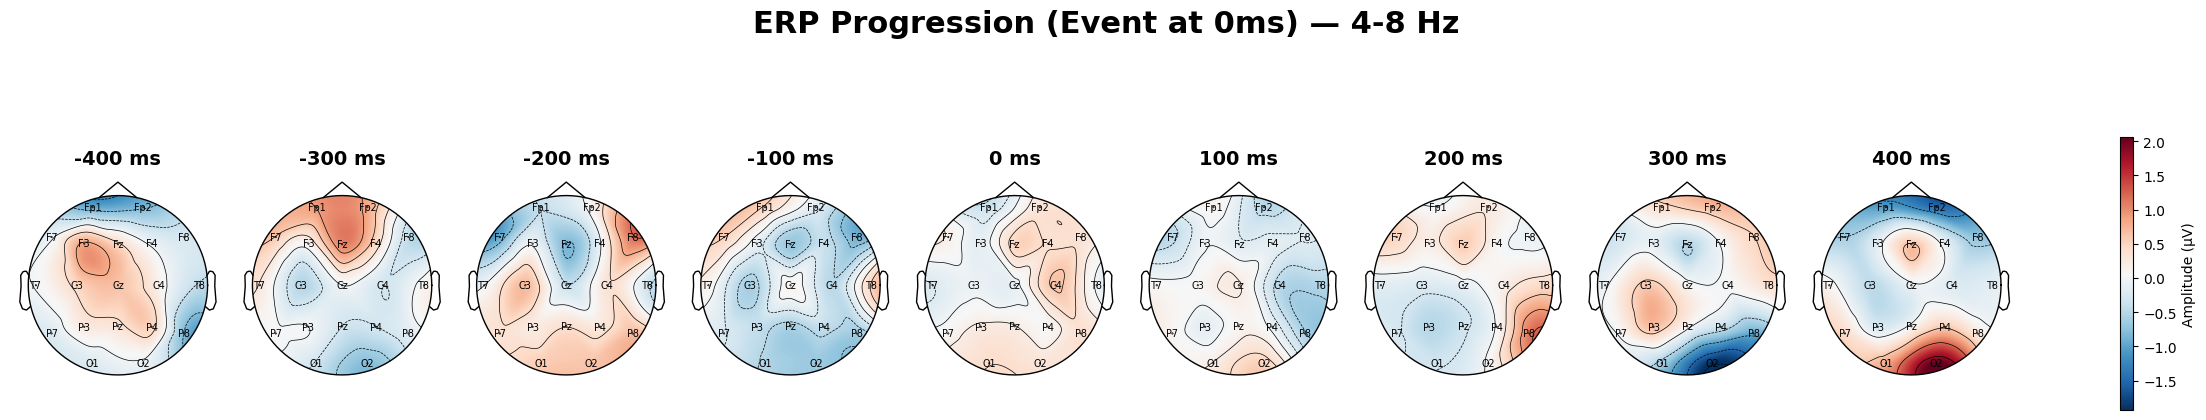

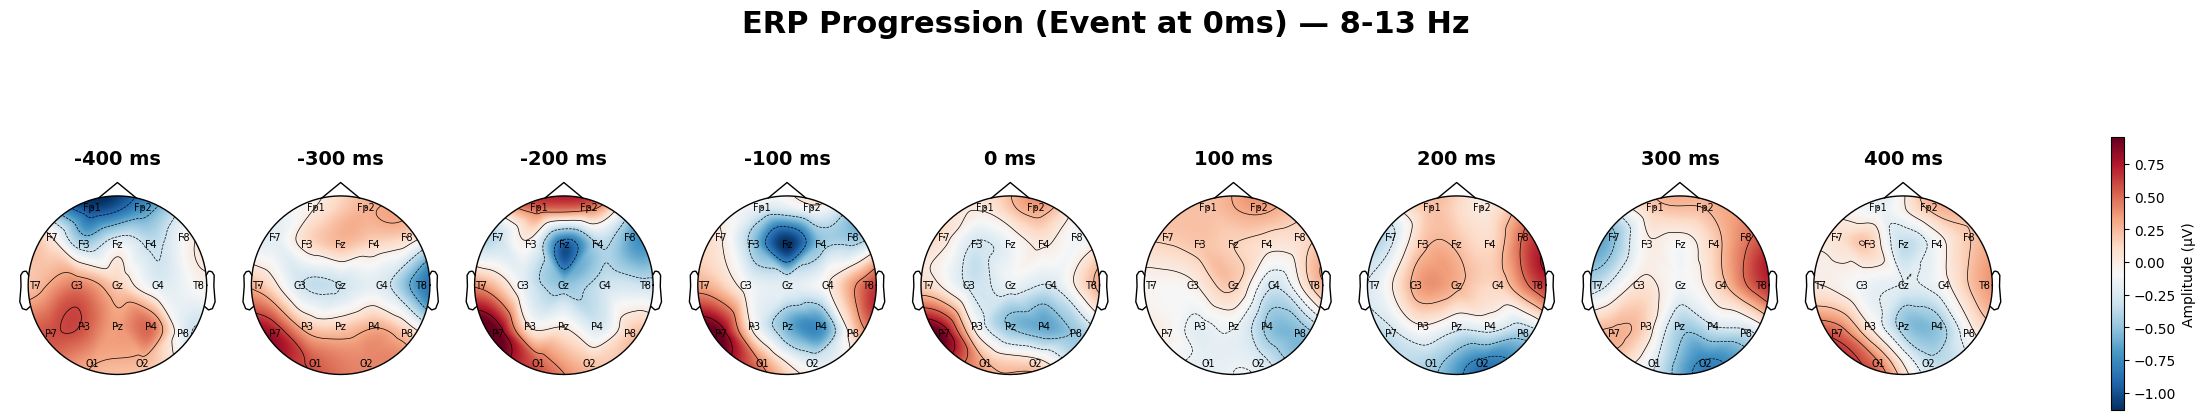

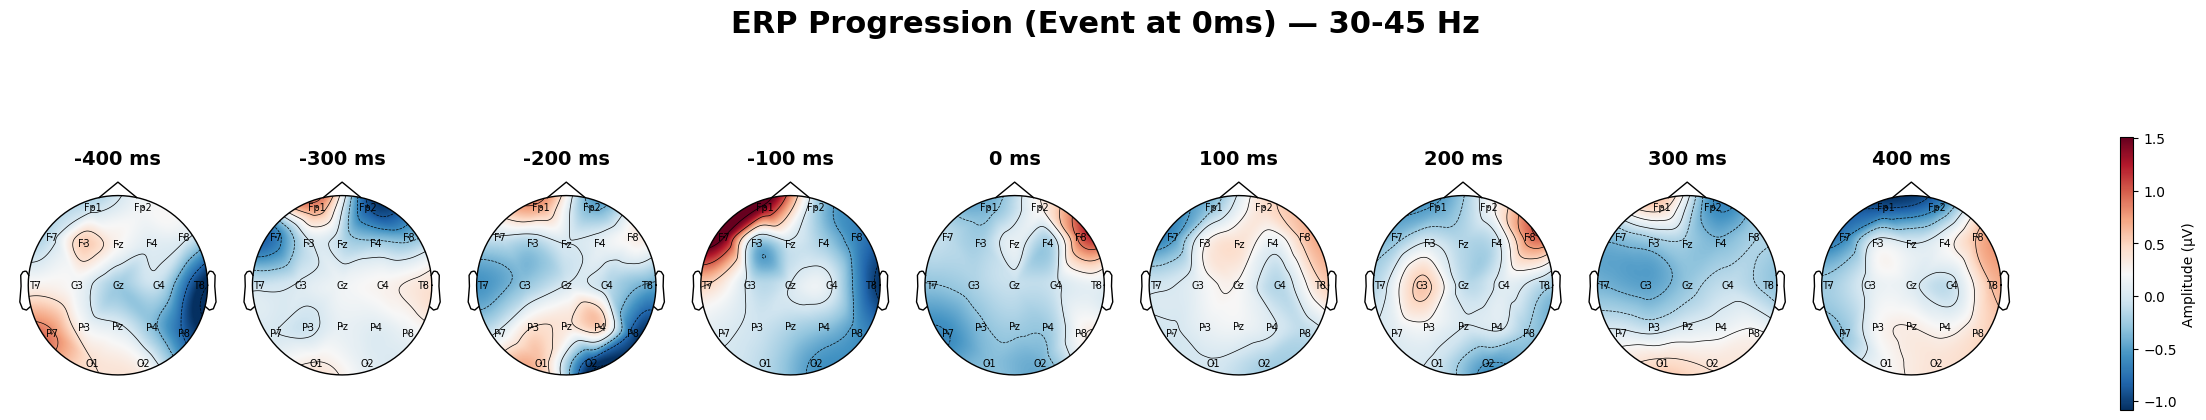

In [7]:

time_slices = [-0.4,-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3, 0.4]
# plot_erp_topomaps_shared(ga_task_treatment, time_slices)
fig, axes = plot_erp_topomaps_shared(ga_task_treatment, time_slices, band=(1, 4))
plt.show()
fig, axes = plot_erp_topomaps_shared(ga_task_treatment, time_slices, band=(4, 8))
plt.show()
fig, axes = plot_erp_topomaps_shared(ga_task_treatment, time_slices, band=(8, 13))
plt.show()
fig, axes= plot_erp_topomaps_shared(ga_task_treatment, time_slices, band=(30, 45))
plt.show()


## Control

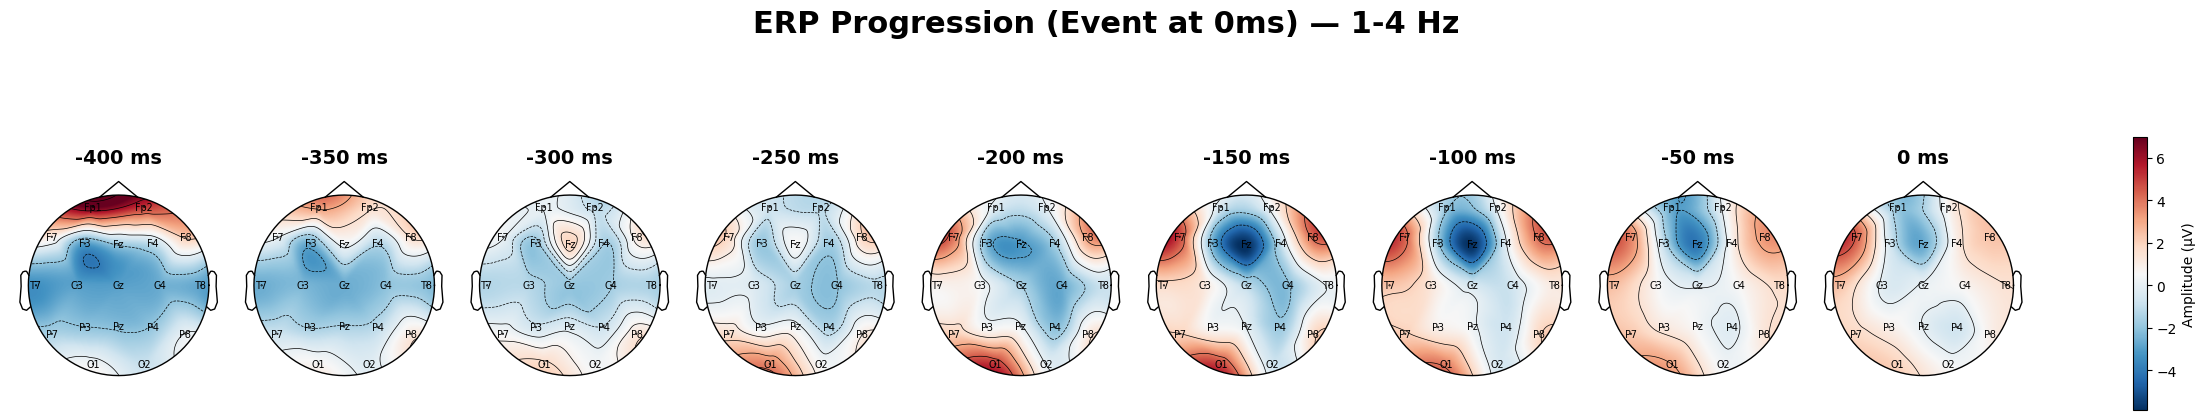

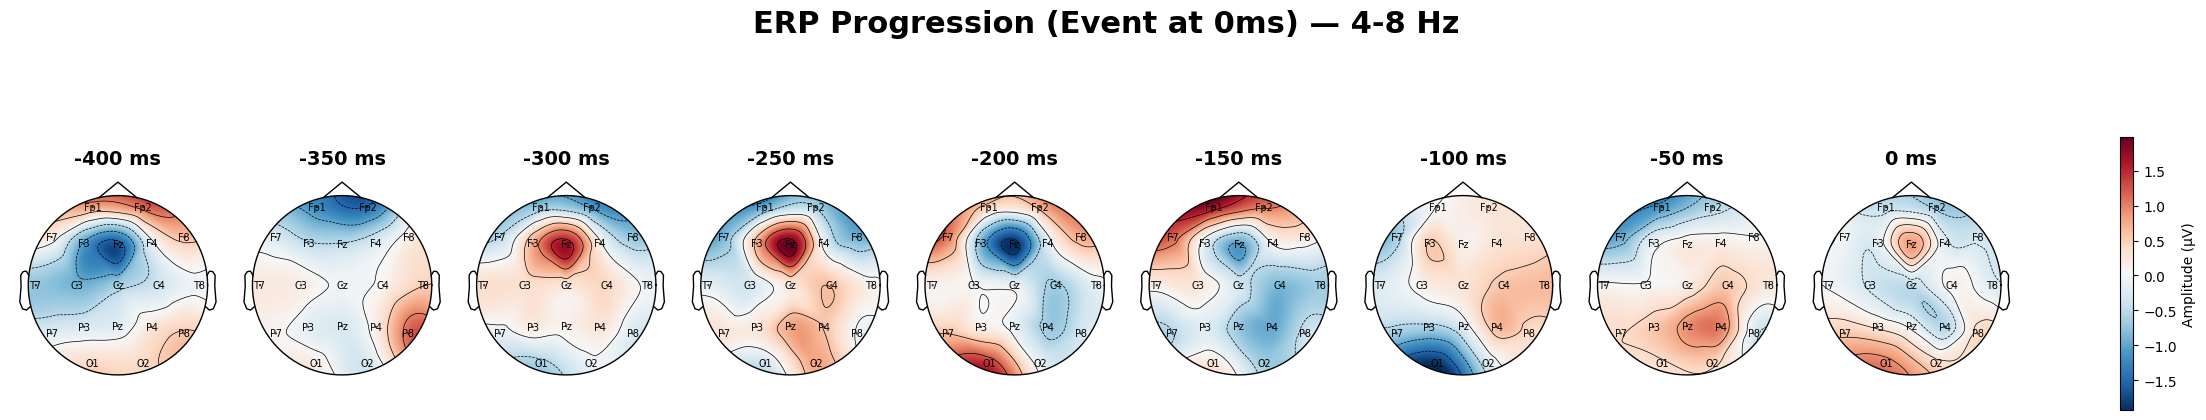

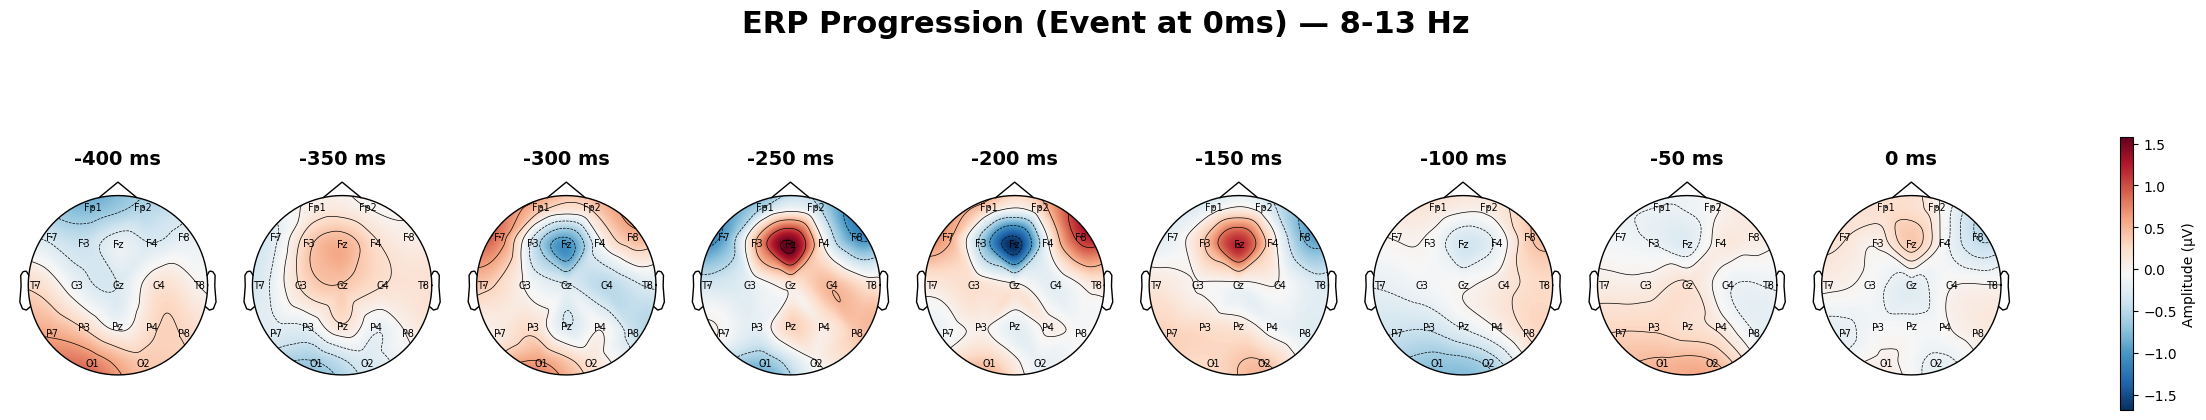

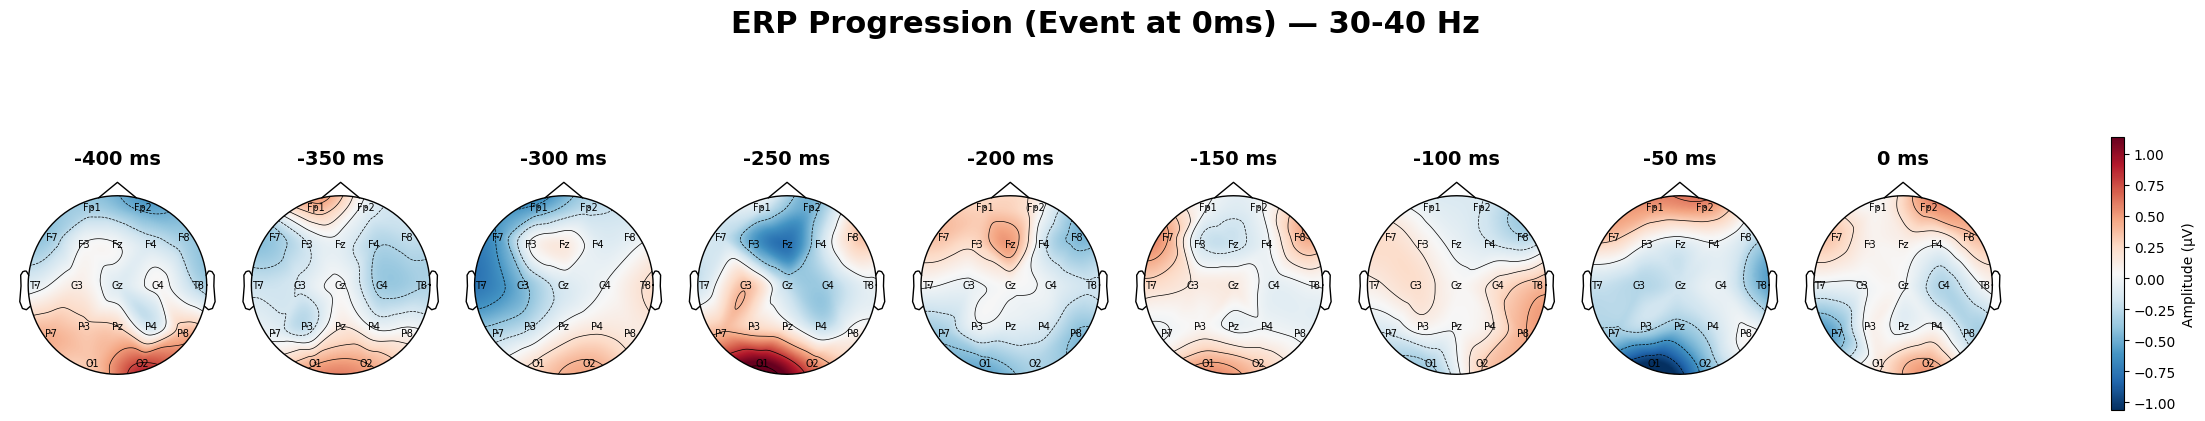

In [8]:
time_slices = [-0.4, -0.35, -0.3, -0.25, -0.2, -0.15, -0.1, -0.05, 0.0]

fig, axes = plot_erp_topomaps_shared(ga_task_control, time_slices, band=(1, 4))
# plt.savefig('erp_topomap_control_delta.png')
plt.show()

fig, axes = plot_erp_topomaps_shared(ga_task_control, time_slices, band=(4, 8))
# plt.savefig('erp_topomap_control_theta.png')
plt.show()

fig, axes = plot_erp_topomaps_shared(ga_task_control, time_slices, band=(8, 13))
# plt.savefig('erp_topomap_control_alpha.png')
plt.show()

fig, axes = plot_erp_topomaps_shared(ga_task_control, time_slices, band=(30, 40))
# plt.savefig('erp_topomap_control_gamma.png')
plt.show()



# Permutation Cluster Test

33 28
15 subjects have both control and treatment sessions and will be included in the analysis.

Running cluster permutation test with 32768 iterations...

STATISTICAL RESULTS
Cluster 52:
  P-value:    0.0378
  Time:       -0.450s to -0.297s
  Direction:  AI > Human (Mean T: -2.69)
  Channels:   P3, C3, F3
--------------------


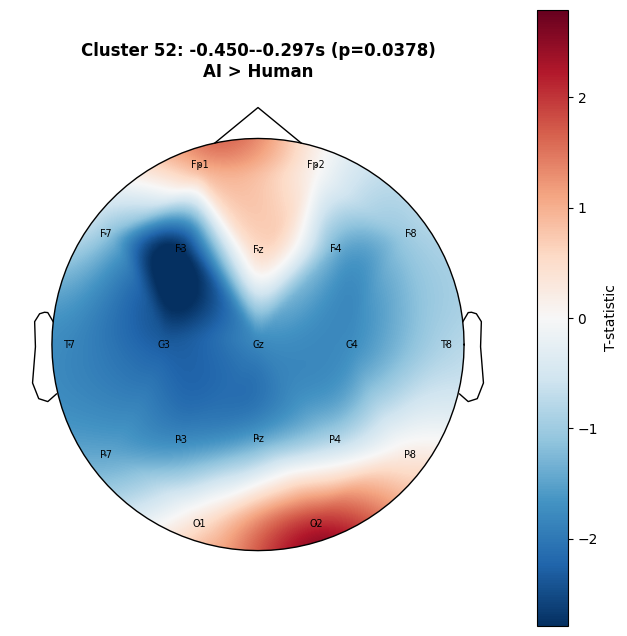

Note: Cluster 52 has a trend-level p-value of 0.0378.

Found 1 significant clusters
Cluster 52: p=0.0378, time=-0.450--0.297s


In [9]:
# Run the test
from utils import run_cluster_permutation_test

print(len(control_files), len(treatment_files))
results = run_cluster_permutation_test(
    control_files=control_files,
    treatment_files=treatment_files,
    get_subject_erp=get_subject_erp,
    standard_chans=standard_chans,
    n_permutations=32768,
    alpha=0.05,
    plot_topomap=True,
    exclude_chans=['A1', 'A2']
)

# Access results
print(f"\nFound {len(results['significant_clusters'])} significant clusters")

# Access specific cluster details
for cluster in results['significant_clusters']:
    print(f"Cluster {cluster['cluster_id']}: "
          f"p={cluster['p_value']:.4f}, "
          f"time={cluster['time_start']:.3f}-{cluster['time_end']:.3f}s")

In [10]:
import numpy as np

for cluster in results['significant_clusters']:
    time_inds = cluster['time_inds']
    chan_inds = cluster['chan_inds']

    # X = control - treatment, shape = subjects x times x channels
    cluster_diff = results['X'][:, time_inds, chan_inds].mean(axis=1)

    cohen_dz = cluster_diff.mean() / cluster_diff.std(ddof=1)
    print(cluster_diff.mean())
    print(f"Cluster {cluster['cluster_id']}: "
          f"p={cluster['p_value']:.4f}, "
          f"time={cluster['time_start']:.3f}-{cluster['time_end']:.3f}s, "
          f"Cohen dz={cohen_dz:.3f}")

-7.273243471336148e-06
Cluster 52: p=0.0378, time=-0.450--0.297s, Cohen dz=-0.824


# Spatio-Temporal cluster Permutation test with adjacency

In [11]:
results_adj = run_cluster_permutation_test(
    control_files=control_files,
    treatment_files=treatment_files,
    get_subject_erp=get_subject_erp,
    standard_chans=standard_chans,
    n_permutations=32768,
    alpha=0.05,
    plot_topomap=True,
    exclude_chans=['A1', 'A2'],
    use_adjacency=True,
    adjacency_threshold=None  # Auto-calculate from t-distribution
)

15 subjects have both control and treatment sessions and will be included in the analysis.

Effect Size Analysis:
  Peak Cohen's d: -0.986
  At time: -0.350s
  At channel: F3

Running cluster permutation test with spatial adjacency...
  Threshold: 1.76
  Permutations: 32768


KeyboardInterrupt: 

In [ ]:
# time_inds_42, chan_inds_42 = np.where(clusters[42])
# start_t = times_vector[np.unique(time_inds_42)[0]]
# end_t = times_vector[np.unique(time_inds_42)[-1]]
# chans_42 = [standard_chans[picks[c]] for c in np.unique(chan_inds_42)]
# print(f"Code 2 Cluster 42: {start_t:.3f}s to {end_t:.3f}s")
# print(f"Channels: {chans_42}")
# for i, p_val in enumerate(cluster_p_values):
#     if p_val < 0.05:
#         time_inds, chan_inds = np.where(clusters[i])
#         start_t = times_vector[np.unique(time_inds)[0]]
#         end_t = times_vector[np.unique(time_inds)[-1]]
#         chans = [standard_chans[picks[c]] for c in np.unique(chan_inds)]
#         print(f"Code 2 Cluster {i}: {start_t:.3f}s to {end_t:.3f}s")
#         print(f"Channels: {chans}")
#         print(f"P-value: {p_val:.4f}")